# 03 Forecast wins vs portfolio wins

**Question: do better forecasts give better portfolios?** The research question has two halves:
do macro-aware forecasts beat the historical-volatility benchmarks in **forecast accuracy**, and do
those gains **translate into better risk-adjusted performance** in volatility-managed portfolios?
Notebook 02 answered the portfolio half pair by pair. This notebook puts the forecast half next
to it: the same pairs, the same 214 out-of-sample months and the same target.

| Section | Question |
|---|---|
| 1 Forecast accuracy | How accurate is each model, against `hist_rw`? |
| 2 Forecast tests | For each block pair, is a's forecast significantly more accurate than b's (Diebold-Mariano)? |
| 3 Pair-level link | When a forecasts better, does a also give the better portfolio? |
| 4 Block verdicts | Each sub-question answered on both sides: the table for the report |
| 5 Ranks | Across all models, do the best forecasters build the best portfolios? |
| 6 Why gains do or do not carry through | Scale, weight distance and cap, calm vs stress months |

**Sign convention**, as in notebook 02: each pair is (a, b), with a the richer model, and a
positive number means a is better (a lower forecast loss, or a higher Sharpe ratio).

The forecast tests here are recomputed on exactly the months the portfolios hold. The model
notebooks remain the main forecast evaluation; their numbers can differ slightly where their
sample differs.

## Setup

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.insert(0, str(Path("..").resolve()))   # models/: research_config and utils

from research_config import BLOCKS
from utils.portfolio_utils import (
    PORTFOLIO_DIR, EVAL_DIR, load_monthly_returns, load_forecast_files, forecast_wide,
    load_portfolios, load_vix_monthly, qlike, dm_table, stars, outcome, verdict,
    weight_distance, pct_capped_pooled, heatmap, style_axis,
    SERIES_COLORS, TEXT_SECONDARY,
)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", "{:.3f}".format)

### Load the saved results

The models, pairs and out-of-sample window come from `results/portfolios/run_info.json`. The
portfolio results come from the tables saved by `02_eval_portfolios.ipynb`, so run 01 and 02
first.

In [2]:
run_info = json.loads((PORTFOLIO_DIR / "run_info.json").read_text())
SELECTED, VARIANTS, TICKERS = run_info["selected"], run_info["variants"], run_info["tickers"]
SPECS, MAIN_SPEC, BENCHMARK, K_CAP = run_info["specs"], run_info["main_spec"], run_info["benchmark"], run_info["k_cap"]
ROBUST_SPEC = next(s for s in SPECS if s != MAIN_SPEC)
pairs = pd.DataFrame(run_info["pairs"]).set_index("pair")
UNITS = TICKERS + ["Cyclical"]
oos_first, oos_last = (pd.Period(m, "M").to_timestamp("M") for m in run_info["oos_window"])

bucket_sr = {s: pd.read_csv(EVAL_DIR / f"vs_benchmarks_bucket_{s}.csv", index_col="portfolio") for s in SPECS}
etf_sr = {s: pd.read_csv(EVAL_DIR / f"vs_benchmarks_per_etf_{s}.csv", index_col=["model", "ETF"]) for s in SPECS}
lw_pairs = pd.read_csv(EVAL_DIR / "pairs.csv").set_index(["spec", "pair", "ETF"]).sort_index()
assert set(etf_sr[MAIN_SPEC].index.get_level_values("model")) == set(VARIANTS), \
    "evaluation tables do not match run_info: rerun 02_eval_portfolios.ipynb"
assert set(lw_pairs.index.get_level_values("pair")) == set(pairs.index), "rerun 02_eval_portfolios.ipynb"

portfolios, xret = load_portfolios(MAIN_SPEC)

print("Models:", VARIANTS)
print(f"Pairs: {list(pairs.index)}")
print(f"Out-of-sample window: {oos_first:%Y-%m} to {oos_last:%Y-%m} | portfolio results: {MAIN_SPEC} σ̄²")

Models: ['hist_rw', 'garch', 'garch_midas_baa10y', 'ols_1m', 'en_no_macro', 'en_no_vix', 'en_full_macro', 'xgb_no_macro', 'xgb_no_vix', 'xgb_vix_only', 'xgb_full_macro']
Pairs: ['B0.1', 'B0.2', 'B1.1', 'B2.1', 'B3.1', 'B4.0', 'B4.1', 'B4.2', 'B4.3', 'B5.1', 'B5.2', 'B5.4']
Out-of-sample window: 2008-03 to 2025-12 | portfolio results: fixed σ̄²


# 1 Forecast accuracy

Forecasts are re-indexed to their holding month t+1 (the row dated t is the forecast for t+1, as
in notebook 01) and restricted to the portfolios' out-of-sample months. Every model is scored
against the same realised variance from the price data:

- **QLIKE** = RV / σ̂² − log(RV / σ̂²) − 1, with σ̂² = `fc_level`. The headline loss: it is robust
  to noise in RV as a proxy for true variance (Patton, 2011) and penalises under-prediction more
  than over-prediction.
- **MSE_log** = (log RV − `fc_log`)²;
- **MSE_level** = (RV − σ̂²)², dominated by a few crisis months.

The `Cyclical` column is the mean across the five ETFs.

In [3]:
_, rv_monthly = load_monthly_returns(TICKERS)
forecasts_raw, _ = load_forecast_files(SELECTED)
oos_idx = rv_monthly.loc[oos_first:oos_last].index
rv = rv_monthly.loc[oos_idx, TICKERS]

fc_level, fc_log = {}, {}
for family, variants in SELECTED.items():
    for v in variants:
        fc_level[v] = forecast_wide(forecasts_raw[family], v, "fc_level", TICKERS).reindex(oos_idx)
        fc_log[v] = forecast_wide(forecasts_raw[family], v, "fc_log", TICKERS).reindex(oos_idx)
        assert not fc_level[v].isna().any().any(), f"{v}: missing forecasts in the OOS window"

losses = {
    "QLIKE": {v: qlike(rv, fc_level[v]) for v in VARIANTS},
    "MSE_log": {v: (np.log(rv) - fc_log[v]) ** 2 for v in VARIANTS},
    "MSE_level": {v: (rv - fc_level[v]) ** 2 for v in VARIANTS},
}
forecast_loss = pd.concat({v: pd.DataFrame({k: losses[k][v].mean() for k in losses}) for v in VARIANTS},
                          names=["model", "ETF"])


def by_unit(loss, models=VARIANTS):
    # models x (ETFs + Cyclical) mean loss
    t = forecast_loss[loss].unstack("ETF").loc[models, TICKERS]
    t["Cyclical"] = t[TICKERS].mean(axis=1)
    return t


qlike_tbl = by_unit("QLIKE")
print("Mean QLIKE (lower is better)")
display(qlike_tbl)
print(f"QLIKE relative to {BENCHMARK} (below 1: more accurate than the historical benchmark)")
display(qlike_tbl / qlike_tbl.loc[BENCHMARK])
print("Mean MSE of log RV (lower is better)")
display(by_unit("MSE_log"))

Mean QLIKE (lower is better)


ETF,XLB,XLE,XLF,XLI,XLY,Cyclical
model,,,,,,
hist_rw,0.359,0.347,0.526,0.420,0.377,0.406
garch,0.241,0.255,0.305,0.260,0.254,0.263
garch_midas_baa10y,0.243,0.259,0.309,0.263,0.256,0.266
ols_1m,0.296,0.296,0.404,0.338,0.297,0.326
en_no_macro,0.296,0.296,0.404,0.338,0.297,0.326
en_no_vix,0.330,0.369,0.460,0.394,0.342,0.379
en_full_macro,0.279,0.357,0.392,0.300,0.293,0.324
xgb_no_macro,0.357,0.361,0.448,0.376,0.395,0.387
xgb_no_vix,0.376,0.423,0.541,0.408,0.381,0.426


QLIKE relative to hist_rw (below 1: more accurate than the historical benchmark)


ETF,XLB,XLE,XLF,XLI,XLY,Cyclical
model,,,,,,
hist_rw,1.000,1.000,1.000,1.000,1.000,1.000
garch,0.672,0.733,0.580,0.620,0.673,0.648
garch_midas_baa10y,0.678,0.745,0.587,0.627,0.679,0.656
ols_1m,0.825,0.851,0.767,0.806,0.787,0.804
en_no_macro,0.825,0.851,0.767,0.806,0.787,0.804
en_no_vix,0.920,1.063,0.875,0.940,0.907,0.934
en_full_macro,0.779,1.027,0.746,0.714,0.776,0.799
xgb_no_macro,0.994,1.038,0.852,0.897,1.047,0.955
xgb_no_vix,1.048,1.216,1.029,0.972,1.009,1.049


Mean MSE of log RV (lower is better)


ETF,XLB,XLE,XLF,XLI,XLY,Cyclical
model,,,,,,
hist_rw,0.540,0.511,0.755,0.629,0.575,0.602
garch,0.434,0.422,0.575,0.457,0.475,0.473
garch_midas_baa10y,0.442,0.432,0.582,0.465,0.479,0.480
ols_1m,0.462,0.451,0.664,0.528,0.504,0.522
en_no_macro,0.462,0.451,0.664,0.528,0.504,0.522
en_no_vix,0.479,0.481,0.669,0.528,0.525,0.536
en_full_macro,0.420,0.468,0.612,0.455,0.491,0.489
xgb_no_macro,0.527,0.489,0.710,0.560,0.618,0.581
xgb_no_vix,0.511,0.502,0.694,0.534,0.543,0.557


### The largest misses

The weight divides by the forecast, so the months where a forecast is furthest from realised
variance are the ones that move a portfolio most. A forecast far **above** realised variance cuts
the position too much; one far **below** it raises the position, often to the cap. The first
table is each model's worst miss in each direction (forecast / realised variance); the second
lists the ten largest over-predictions, with both shown as annualised volatility.

In [4]:
misses = pd.DataFrame({
    "forecast": pd.concat({v: fc_level[v].stack() for v in VARIANTS}),
    "realised": pd.concat({v: rv.stack() for v in VARIANTS}),
}).rename_axis(["model", "holding_month", "ETF"])
misses["forecast / realised"] = misses["forecast"] / misses["realised"]
# Shown as annualised volatility (%), easier to read than monthly variance
for col in ["forecast", "realised"]:
    misses[f"{col} vol % p.a."] = np.sqrt(12 * misses.pop(col)) * 100

worst = misses.groupby("model", sort=False)["forecast / realised"].agg(
    max_over="max", month_of_max="idxmax", max_under="min", month_of_min="idxmin")
worst["month_of_max"] = [f"{m[2]} {m[1]:%Y-%m}" for m in worst["month_of_max"]]
worst["month_of_min"] = [f"{m[2]} {m[1]:%Y-%m}" for m in worst["month_of_min"]]
display(worst)
display(misses.nlargest(10, "forecast / realised"))

,max_over,month_of_max,max_under,month_of_min
model,,,,
hist_rw,15.138,XLF 2014-11,0.051,XLF 2020-03
garch,11.096,XLF 2014-11,0.078,XLE 2020-03
garch_midas_baa10y,11.074,XLF 2014-11,0.078,XLE 2020-03
ols_1m,21.303,XLF 2014-11,0.056,XLI 2020-03
en_no_macro,21.338,XLF 2014-11,0.056,XLI 2020-03
en_no_vix,16.355,XLF 2014-11,0.031,XLF 2020-03
en_full_macro,16.741,XLI 2008-11,0.056,XLE 2008-10
xgb_no_macro,21.205,XLF 2014-11,0.047,XLI 2020-03
xgb_no_vix,18.420,XLF 2014-11,0.028,XLF 2020-03


,,,forecast / realised,forecast vol % p.a.,realised vol % p.a.
model,holding_month,ETF,,,
en_no_macro,2014-11-30,XLF,21.338,22.853,4.947
ols_1m,2014-11-30,XLF,21.303,22.834,4.947
xgb_no_macro,2014-11-30,XLF,21.205,22.782,4.947
xgb_no_vix,2014-11-30,XLF,18.420,21.233,4.947
en_full_macro,2008-11-30,XLI,16.741,219.609,53.673
en_no_vix,2014-11-30,XLF,16.355,20.008,4.947
xgb_vix_only,2014-11-30,XLF,15.660,19.578,4.947
en_full_macro,2008-11-30,XLY,15.247,288.767,73.952
hist_rw,2014-11-30,XLF,15.138,19.249,4.947


# 2 Forecast tests: the same pairs as the portfolio tests

For each block pair, a **Diebold-Mariano** test of equal expected loss, with the
Harvey-Leybourne-Newbold small-sample correction and Newey-West variance (`dm_test` in
`utils/portfolio_utils.py`). Per ETF the loss difference is dₜ = L(a)ₜ − L(b)ₜ; for the cyclical
bucket it is the mean of dₜ across the five ETFs.

- **gain t** = −DM t, so a positive value means a forecasts more accurately;
- **QLIKE gain %** = the share of b's mean QLIKE that a removes (negative: a is worse);
- MSE_log is the secondary loss.

In [5]:
dm = pd.concat({(loss, pid): dm_table(losses[loss][p.a], losses[loss][p.b])
                for loss in ["QLIKE", "MSE_log"] for pid, p in pairs.iterrows()},
               names=["loss", "pair"]).sort_index()


def forecast_rows(unit="Cyclical"):
    rows = {}
    for pid, p in pairs.iterrows():
        q, m = dm.loc[("QLIKE", pid, unit)], dm.loc[("MSE_log", pid, unit)]
        rows[pid] = {
            "block": p.block, "a": p.a, "b": p.b, "isolates": p.isolates,
            "QLIKE gain %": -q.mean_loss_diff / qlike_tbl.at[p.b, unit] * 100,
            "gain t": q.gain_t, "p": q.DM_p, "sig": stars(q.DM_p), "result": outcome(q.gain_t, q.DM_p),
            "MSE_log gain t": m.gain_t, "MSE_log p": m.DM_p,
        }
    return pd.DataFrame(rows).T.rename_axis("pair")


forecast_board = forecast_rows()
display(forecast_board)
for pid, r in forecast_board.iterrows():
    print(verdict(pid, r.a, r.b, r["gain t"], r.p, label="QLIKE gain t", noun="forecast"))

,block,a,b,isolates,QLIKE gain %,gain t,p,sig,result,MSE_log gain t,MSE_log p
pair,,,,,,,,,,,
B0.1,B0,garch,hist_rw,fitted GARCH vs naive history,35.167,3.997,0.000,***,a better,3.665,0.000
B0.2,B0,ols_1m,hist_rw,fitted AR(1) on log RV vs naive history,19.639,3.256,0.001,***,a better,3.859,0.000
B1.1,B1,garch_midas_baa10y,garch,credit spread (BAA10Y) as the long-run component,-1.126,-1.848,0.066,*,a worse,-1.434,0.153
B2.1,B2,en_full_macro,ols_1m,total effect of macro + VIX,0.585,0.085,0.933,,n.s.,0.944,0.346
B3.1,B3,en_full_macro,en_no_vix,VIX on top of the other macro variables,14.504,1.461,0.145,,n.s.,2.474,0.014
B4.0,B4,xgb_full_macro,xgb_no_macro,total effect of macro + VIX,-2.249,-0.328,0.743,,n.s.,2.772,0.006
B4.1,B4,xgb_full_macro,xgb_no_vix,VIX on top of the other macro variables,6.937,0.957,0.339,,n.s.,2.529,0.012
B4.2,B4,xgb_vix_only,xgb_no_macro,VIX on its own,6.389,2.167,0.031,**,a better,3.694,0.000
B4.3,B4,xgb_full_macro,xgb_vix_only,other macro variables on top of VIX,-9.228,-1.489,0.138,,n.s.,0.468,0.640


B0.1: garch gives a significantly better forecast than hist_rw (QLIKE gain t +3.997, p = 0.000)
B0.2: ols_1m gives a significantly better forecast than hist_rw (QLIKE gain t +3.256, p = 0.001)
B1.1: garch_midas_baa10y gives a weakly significantly worse forecast than garch (QLIKE gain t -1.848, p = 0.066)
B2.1: no significant difference between en_full_macro and ols_1m (QLIKE gain t +0.085, p = 0.933)
B3.1: no significant difference between en_full_macro and en_no_vix (QLIKE gain t +1.461, p = 0.145)
B4.0: no significant difference between xgb_full_macro and xgb_no_macro (QLIKE gain t -0.328, p = 0.743)
B4.1: no significant difference between xgb_full_macro and xgb_no_vix (QLIKE gain t +0.957, p = 0.339)
B4.2: xgb_vix_only gives a significantly better forecast than xgb_no_macro (QLIKE gain t +2.167, p = 0.031)
B4.3: no significant difference between xgb_full_macro and xgb_vix_only (QLIKE gain t -1.489, p = 0.138)
B5.1: no significant difference between xgb_no_macro and en_no_macro (QLIK

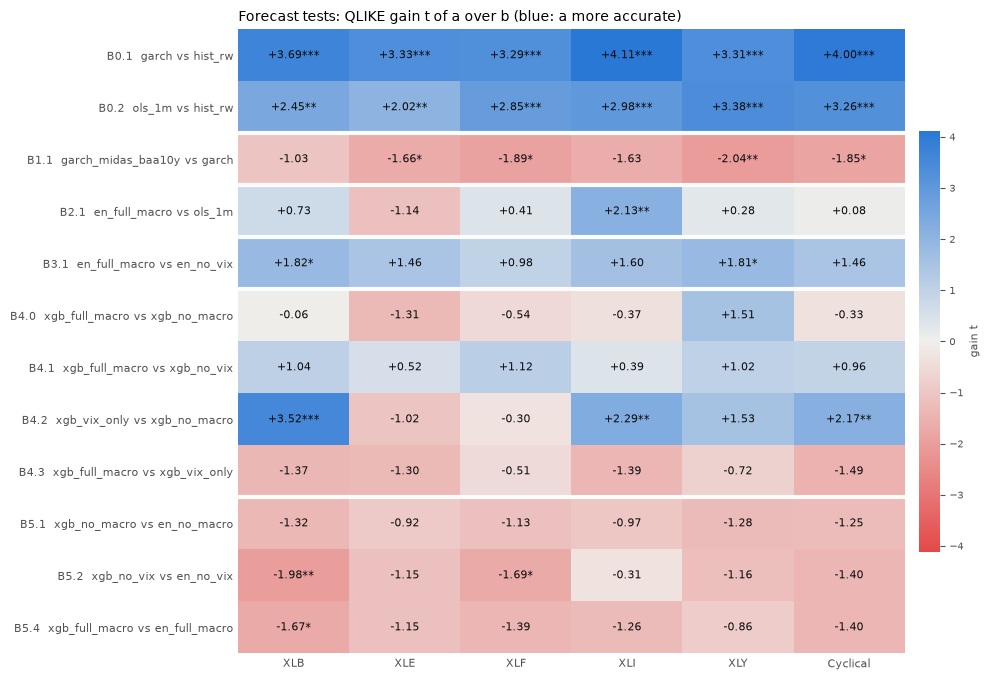

In [6]:
labels = [f"{pid}  {p.a} vs {p.b}" for pid, p in pairs.iterrows()]
gain_t = pd.DataFrame([[dm.loc[("QLIKE", pid, u), "gain_t"] for u in UNITS] for pid in pairs.index],
                      index=labels, columns=UNITS)
gain_p = pd.DataFrame([[dm.loc[("QLIKE", pid, u), "DM_p"] for u in UNITS] for pid in pairs.index],
                      index=labels, columns=UNITS)

fig, ax = plt.subplots(figsize=(10, 0.45 * len(pairs) + 1.5))
heatmap(gain_t, gain_p, ax, "Forecast tests: QLIKE gain t of a over b (blue: a more accurate)",
        center_label="gain t")
breaks = np.flatnonzero(pairs["block"].to_numpy()[1:] != pairs["block"].to_numpy()[:-1])
for y in breaks:
    ax.axhline(y + 0.5, color="#fcfcfb", linewidth=3)
fig.tight_layout()
plt.show()

**Interpretation: the forecast half of the research question.**

- **Against the naive historical benchmark (section 1, B0):** almost every model forecasts more
  accurately than `hist_rw` (QLIKE ratio below 1 for the bucket; only `xgb_no_vix` is above). The
  fitted historical models gain the most, and significantly: GARCH removes 35% of `hist_rw`'s
  QLIKE (t = 4.0) and HAR-OLS 20% (t = 3.3).
- **Against the best historical model:** GARCH has the lowest QLIKE in every ETF. No macro-aware
  model beats it, and `en_full_macro` (QLIKE ratio 0.80) only matches HAR-OLS (0.80).
- **Macro within GARCH (B1):** the credit spread makes GARCH-MIDAS slightly *less* accurate
  (−1%, p = 0.07).
- **Macro + VIX in a linear model (B2):** no accuracy gain over HAR-OLS for the bucket (+0.6%,
  p = 0.93).
- **VIX is the useful macro input.** In Elastic Net, adding VIX to the other macro variables
  removes 15% of the QLIKE (B3.1; significant on MSE_log, p = 0.01, though not on QLIKE). In
  XGBoost, VIX on its own significantly improves accuracy (B4.2, +6%, p = 0.03). Adding the
  other macro variables on top of VIX makes XGBoost less accurate (B4.3, −9%, n.s.). On the
  forecast side the reading key gives "VIX is doing the work". The non-VIX variables add noise,
  so the total effect of macro + VIX is about zero on QLIKE (B4.0).
- **Non-linearity (B5):** XGBoost is less accurate than Elastic Net for every information set
  (−12% to −22% QLIKE), though not significantly.

**So:** macro-aware forecasts beat the naive random walk, but not the fitted historical
benchmarks. The one macro input with a measurable forecast gain is VIX.

# 3 Pair-level link: do forecast wins carry into portfolio wins?

Each point is one pair in one unit (5 ETFs + the cyclical bucket): the forecast test on the x-axis
and the portfolio test (Ledoit-Wolf, fixed σ̄², from notebook 02) on the y-axis. Both are oriented
so that positive means a is better.

- **Top-right / bottom-left:** forecast and portfolio agree.
- **Bottom-right:** a better forecast that gives a worse portfolio, so the gain is lost on the way.
- Dotted lines: ±1.96.

In [7]:
lw_main = lw_pairs.loc[MAIN_SPEC]
rows = []
for pid, p in pairs.iterrows():
    for unit in UNITS:
        f, q = dm.loc[("QLIKE", pid, unit)], lw_main.loc[(pid, unit)]
        rows.append({
            "block": p.block, "pair": pid, "unit": unit, "a": p.a, "b": p.b,
            "forecast gain t": f.gain_t, "DM p": f.DM_p, "forecast result": outcome(f.gain_t, f.DM_p),
            "ΔSR": q.SR_diff, "LW t": q.LW_t, "LW p": q.LW_p, "portfolio result": outcome(q.SR_diff, q.LW_p),
            "same direction": bool(np.sign(f.gain_t) == np.sign(q.SR_diff)),
        })
link = pd.DataFrame(rows).set_index(["pair", "unit"])
bucket_link = link.xs("Cyclical", level="unit")

agreement = pd.DataFrame({
    "all points": [link["same direction"].mean(), link["forecast gain t"].corr(link["LW t"], method="spearman"), len(link)],
    "bucket only": [bucket_link["same direction"].mean(),
                    bucket_link["forecast gain t"].corr(bucket_link["LW t"], method="spearman"), len(bucket_link)],
}, index=["share in the same direction", "Spearman ρ (forecast t, LW t)", "points"])
display(agreement)
print("By block, share of points in the same direction:")
display(link.groupby("block")["same direction"].agg(["mean", "size"]).T)
print("Forecast result (rows) against portfolio result (columns), all points, 10% level:")
display(pd.crosstab(link["forecast result"], link["portfolio result"], margins=True))

,all points,bucket only
share in the same direction,0.583,0.583
"Spearman ρ (forecast t, LW t)",0.188,0.434
points,72.000,12.000


By block, share of points in the same direction:


block,B0,B1,B2,B3,B4,B5
mean,0.583,0.833,0.167,0.333,0.542,0.778
size,12.000,6.000,6.000,6.000,24.000,18.000


Forecast result (rows) against portfolio result (columns), all points, 10% level:


portfolio result,a worse,n.s.,All
forecast result,,,
a better,0,18,18
a worse,0,7,7
n.s.,6,41,47
All,6,66,72


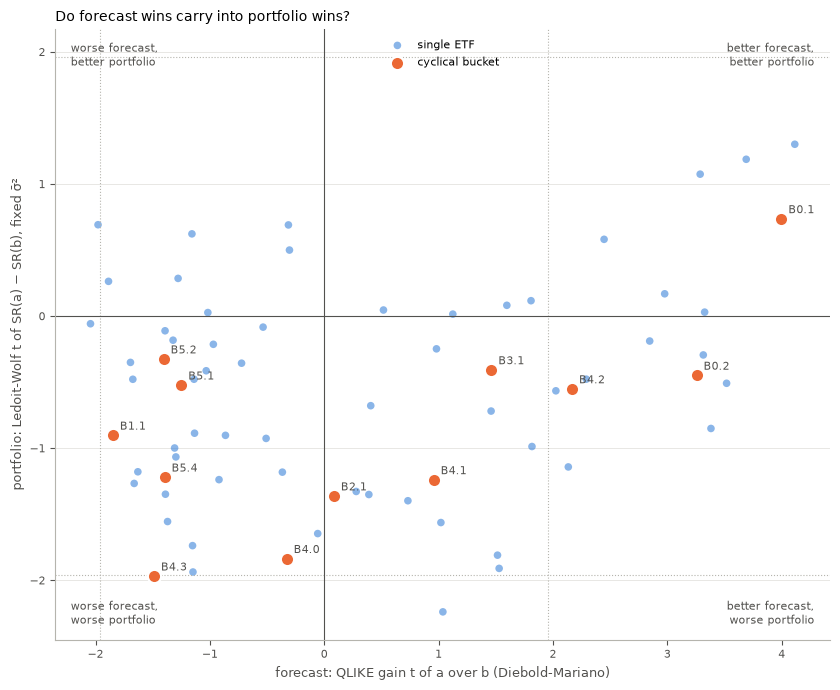

In [8]:
pts = link.reset_index()
etf_pts, bkt_pts = pts[pts["unit"] != "Cyclical"], pts[pts["unit"] == "Cyclical"]

fig, ax = plt.subplots(figsize=(8.5, 7))
ax.scatter(etf_pts["forecast gain t"], etf_pts["LW t"], s=30, color=SERIES_COLORS[0], alpha=0.55,
           edgecolor="none", label="single ETF")
ax.scatter(bkt_pts["forecast gain t"], bkt_pts["LW t"], s=90, color=SERIES_COLORS[1],
           edgecolor="white", linewidth=1.5, zorder=3, label="cyclical bucket")
for _, r in bkt_pts.iterrows():
    ax.annotate(r["pair"], (r["forecast gain t"], r["LW t"]), xytext=(5, 4), textcoords="offset points",
                fontsize=8, color=TEXT_SECONDARY)
for v in (-1.96, 1.96):
    ax.axhline(v, color="#b5b4ad", linewidth=0.8, linestyle=":")
    ax.axvline(v, color="#b5b4ad", linewidth=0.8, linestyle=":")
ax.axhline(0, color="#52514e", linewidth=0.8)
ax.axvline(0, color="#52514e", linewidth=0.8)
corner = dict(transform=ax.transAxes, fontsize=8, color=TEXT_SECONDARY)
ax.text(0.98, 0.98, "better forecast,\nbetter portfolio", ha="right", va="top", **corner)
ax.text(0.02, 0.02, "worse forecast,\nworse portfolio", ha="left", va="bottom", **corner)
ax.text(0.98, 0.02, "better forecast,\nworse portfolio", ha="right", va="bottom", **corner)
ax.text(0.02, 0.98, "worse forecast,\nbetter portfolio", ha="left", va="top", **corner)
ax.set_xlabel("forecast: QLIKE gain t of a over b (Diebold-Mariano)", fontsize=9, color=TEXT_SECONDARY)
ax.set_ylabel(f"portfolio: Ledoit-Wolf t of SR(a) − SR(b), {MAIN_SPEC} σ̄²", fontsize=9, color=TEXT_SECONDARY)
ax.set_title("Do forecast wins carry into portfolio wins?", fontsize=10, loc="left")
style_axis(ax)
ax.legend(fontsize=8, frameon=False, loc="upper center")
fig.tight_layout()
plt.show()

**Interpretation.** **Forecast wins do not carry into portfolio wins.** Forecast and portfolio
point the same way in only 58% of pair-units, barely more than a coin flip, and the rank
correlation between the two test statistics is 0.19 (0.43 for the bucket alone).

The cross-table is the sharpest evidence. **Of the 18 significant forecast wins, not one gives a
significant portfolio win.** All six significant portfolio results are losses for the richer
model, and they come from pairs whose forecasts were *not* significantly different. No point is
significant on both sides.

By block, the agreement is highest where both sides say "no gain": B1, and B5, where XGBoost is
worse on both. It is lowest for the Elastic Net macro pairs, B2 (17%) and B3 (33%), where adding
macro information nudges forecast accuracy up while the portfolio gets worse.

# 4 Block verdicts: both halves of the research question

One row per pair, for the cyclical bucket: the forecast result (QLIKE Diebold-Mariano), the
portfolio result under each σ̄² specification (Ledoit-Wolf), and whether forecast and portfolio
agree. Results are at the 10% level: "a better", "a worse" or "n.s.".

In [9]:
lw_rob = lw_pairs.loc[ROBUST_SPEC]
verdicts = pd.DataFrame({
    pid: {
        "block": p.block, "question": BLOCKS[p.block]["title"], "a": p.a, "b": p.b, "isolates": p.isolates,
        "QLIKE gain %": forecast_board.at[pid, "QLIKE gain %"],
        "forecast": f"{bucket_link.at[pid, 'forecast result']} ({bucket_link.at[pid, 'forecast gain t']:+.2f}{stars(bucket_link.at[pid, 'DM p'])})",
        "ΔSR": bucket_link.at[pid, "ΔSR"],
        f"portfolio ({MAIN_SPEC})": f"{bucket_link.at[pid, 'portfolio result']} ({bucket_link.at[pid, 'ΔSR']:+.3f}{stars(bucket_link.at[pid, 'LW p'])})",
        f"portfolio ({ROBUST_SPEC})": f"{outcome(lw_rob.at[(pid, 'Cyclical'), 'SR_diff'], lw_rob.at[(pid, 'Cyclical'), 'LW_p'])} "
                                      f"({lw_rob.at[(pid, 'Cyclical'), 'SR_diff']:+.3f}{stars(lw_rob.at[(pid, 'Cyclical'), 'LW_p'])})",
        "same result": bucket_link.at[pid, "forecast result"] == bucket_link.at[pid, "portfolio result"],
        "same direction": bucket_link.at[pid, "same direction"],
    }
    for pid, p in pairs.iterrows()
}).T.rename_axis("pair")
verdicts

,block,question,a,b,isolates,QLIKE gain %,forecast,ΔSR,portfolio (fixed),portfolio (expanding),same result,same direction
pair,,,,,,,,,,,,
B0.1,B0,Volatility-timing baseline,garch,hist_rw,fitted GARCH vs naive history,35.167,a better (+4.00***),0.029,n.s. (+0.029),n.s. (+0.005),False,True
B0.2,B0,Volatility-timing baseline,ols_1m,hist_rw,fitted AR(1) on log RV vs naive history,19.639,a better (+3.26***),-0.014,n.s. (-0.014),n.s. (-0.010),False,False
B1.1,B1,GARCH family,garch_midas_baa10y,garch,credit spread (BAA10Y) as the long-run component,-1.126,a worse (-1.85*),-0.003,n.s. (-0.003),n.s. (+0.000),False,True
B2.1,B2,Macro information in a linear model,en_full_macro,ols_1m,total effect of macro + VIX,0.585,n.s. (+0.08),-0.055,n.s. (-0.055),n.s. (-0.054),True,False
B3.1,B3,"Effect of VIX, Elastic Net",en_full_macro,en_no_vix,VIX on top of the other macro variables,14.504,n.s. (+1.46),-0.017,n.s. (-0.017),n.s. (-0.011),True,False
B4.0,B4,"Effect of VIX, XGBoost (robustness check for B3)",xgb_full_macro,xgb_no_macro,total effect of macro + VIX,-2.249,n.s. (-0.33),-0.091,a worse (-0.091*),a worse (-0.106**),False,True
B4.1,B4,"Effect of VIX, XGBoost (robustness check for B3)",xgb_full_macro,xgb_no_vix,VIX on top of the other macro variables,6.937,n.s. (+0.96),-0.061,n.s. (-0.061),n.s. (-0.051),True,False
B4.2,B4,"Effect of VIX, XGBoost (robustness check for B3)",xgb_vix_only,xgb_no_macro,VIX on its own,6.389,a better (+2.17**),-0.024,n.s. (-0.024),a worse (-0.073**),False,False
B4.3,B4,"Effect of VIX, XGBoost (robustness check for B3)",xgb_full_macro,xgb_vix_only,other macro variables on top of VIX,-9.228,n.s. (-1.49),-0.067,a worse (-0.067*),n.s. (-0.033),False,True


**Interpretation: answering the research question.**

1. **Forecast accuracy.** Macro-aware forecasts beat the naive historical benchmark, but so does
   every fitted historical model. **None beats GARCH**, the strongest historical-volatility
   benchmark. The only macro input with a measurable gain is **VIX** (B3.1 in Elastic Net, B4.2
   in XGBoost). The other macro variables, and non-linearity, do not improve accuracy.
2. **Portfolio performance.** **None of these forecast gains translates into a significantly
   better volatility-managed portfolio.** The largest forecast gains in the study, the fitted
   models over the random walk (B0, t = 3–4), give Sharpe-ratio differences of only +0.03 and −0.01. The VIX
   gains give slightly lower Sharpe ratios. Where the portfolio results are significant, they
   are losses from adding macro information to XGBoost.

The "same result" column is mostly False for a consistent reason: forecast tests detect
differences that the portfolio tests do not. Section 6 shows why.

# 5 Ranks: do the best forecasters build the best portfolios?

Across all models at once, per ETF and for the bucket: the model with the lowest QLIKE, the model
with the highest Sharpe ratio, and the Spearman rank correlation between forecast accuracy
(−QLIKE) and Sharpe ratio. `en_no_macro` is left out because its forecasts are identical to
`ols_1m`'s (checked below), so it would count the same forecast twice. With ten models, ρ is
descriptive rather than a test.

In [10]:
print("Correlation of en_no_macro and ols_1m forecasts:",
      f"{np.corrcoef(fc_level['en_no_macro'].to_numpy().ravel(), fc_level['ols_1m'].to_numpy().ravel())[0, 1]:.7f}")
rank_models = [m for m in VARIANTS if m != "en_no_macro"]

q_rank = qlike_tbl.loc[rank_models]
sharpe_tbl = etf_sr[MAIN_SPEC]["SR_managed"].unstack("ETF").loc[rank_models, TICKERS]
sharpe_tbl["Cyclical"] = bucket_sr[MAIN_SPEC].loc[rank_models, "ann_sharpe"]


def rank_summary(q, sr):
    out = pd.DataFrame({
        "best_forecast_model": q.idxmin(),
        "best_portfolio_model": sr.idxmax(),
        "spearman_rho": pd.Series({u: (-q[u]).corr(sr[u], method="spearman") for u in q.columns}),
    })
    out.insert(2, "same_model", out["best_forecast_model"] == out["best_portfolio_model"])
    out["SR_of_best_forecast_model"] = [sr.at[m, u] for u, m in out["best_forecast_model"].items()]
    out["SR_of_best_portfolio_model"] = sr.max()
    return out.rename_axis("unit")


ranks = rank_summary(q_rank, sharpe_tbl)
display(pd.concat({"QLIKE rank": q_rank.rank(), "SR rank": sharpe_tbl.rank(ascending=False)}, axis=1).astype(int))
ranks

Correlation of en_no_macro and ols_1m forecasts: 0.9999997


QLIKE rank                          SR rank                         
ETF                       XLB XLE XLF XLI XLY Cyclical     XLB XLE XLF XLI XLY Cyclical
model                                                                                  
hist_rw                     9   4   9  10   8        9       6   2   3   4   1        3
garch                       1   1   1   1   1        1       1   1   2   1   3        1
garch_midas_baa10y          2   2   2   2   2        2       2   3   1   2   4        2
ols_1m                      4   3   4   5   4        4       4   4   4   3   5        4
en_no_vix                   6   7   6   8   7        6       7   5   6   9   8        6
en_full_macro               3   5   3   3   3        3       9   6   7   8   7        8
xgb_no_macro                7   6   5   6  10        7       5   8   8   5   2        5
xgb_no_vix                 10  10  10   9   9       10       3  10  10   6   6        9
xgb_vix_only                5   8   7   4   5        5       8   7   5   7   9        7
xgb_full_macro              8   9   8   7   6        8      10   9   9  10  10       10

,best_forecast_model,best_portfolio_model,same_model,spearman_rho,SR_of_best_forecast_model,SR_of_best_portfolio_model
unit,,,,,,
XLB,garch,garch,True,0.321,0.233,0.233
XLE,garch,garch,True,0.903,0.120,0.120
XLF,garch,garch_midas_baa10y,False,0.588,0.596,0.596
XLI,garch,garch,True,0.430,0.606,0.606
XLY,garch,hist_rw,False,-0.091,0.807,0.822
Cyclical,garch,garch,True,0.552,0.497,0.497


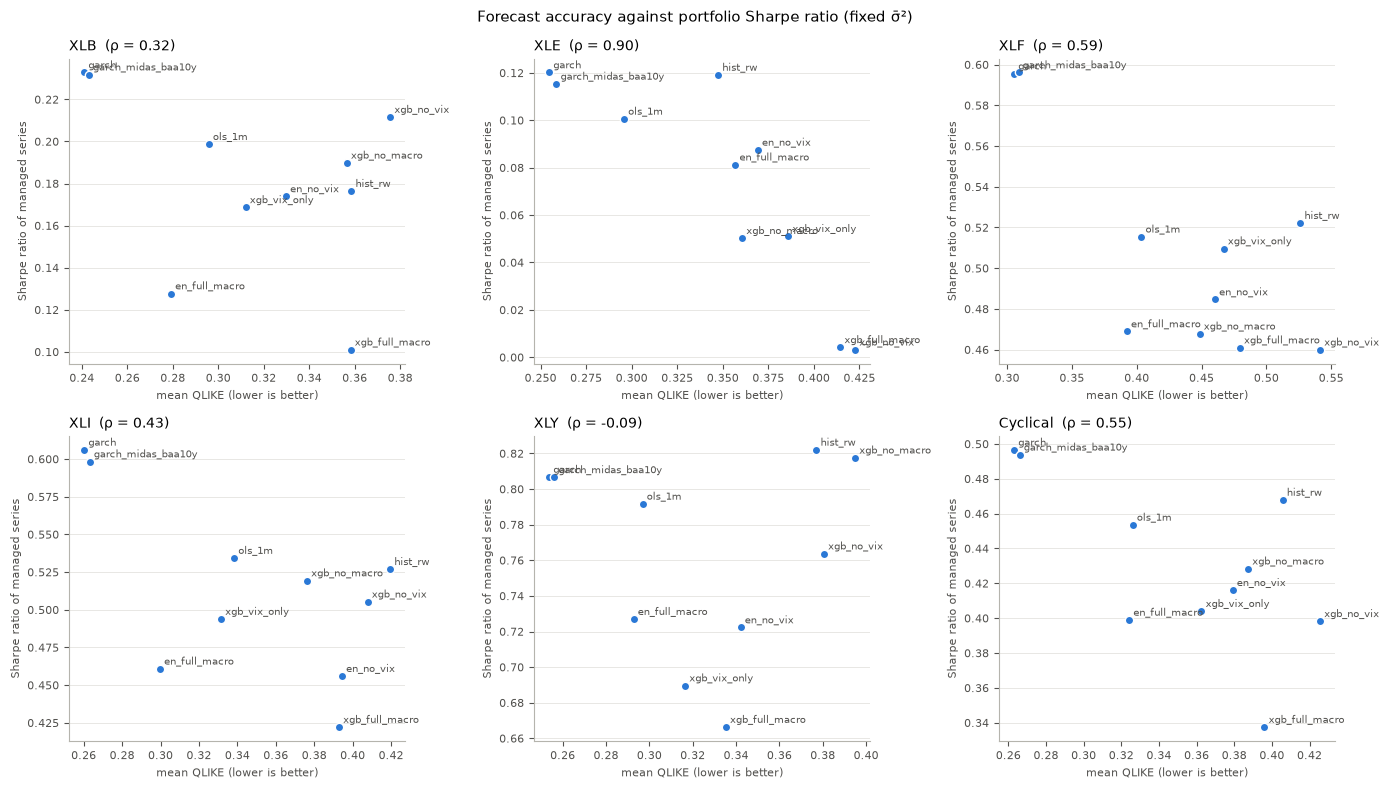

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8), squeeze=False)
for ax, u in zip(axes.flat, UNITS):
    ax.scatter(q_rank[u], sharpe_tbl[u], s=36, color=SERIES_COLORS[0], edgecolor="white", linewidth=1)
    for m in rank_models:
        ax.annotate(m, (q_rank.at[m, u], sharpe_tbl.at[m, u]), fontsize=7, color=TEXT_SECONDARY,
                    xytext=(3, 3), textcoords="offset points")
    ax.set_title(f"{u}  (ρ = {ranks.at[u, 'spearman_rho']:.2f})", fontsize=10, loc="left")
    ax.set_xlabel("mean QLIKE (lower is better)", fontsize=8, color=TEXT_SECONDARY)
    ax.set_ylabel("Sharpe ratio of managed series", fontsize=8, color=TEXT_SECONDARY)
    style_axis(ax)
fig.suptitle(f"Forecast accuracy against portfolio Sharpe ratio ({MAIN_SPEC} σ̄²)", fontsize=11)
fig.tight_layout()
plt.show()

**Interpretation.** At the level of the whole model set, accuracy and portfolio performance are
**positively related** (ρ = 0.55 for the bucket, 0.90 for XLE). That is mainly because GARCH is
top on both and XGBoost with full macro is near the bottom on both. GARCH is the most accurate
model for every ETF and builds the best portfolio for the bucket, XLB, XLE and XLI. So the
broad ordering carries through, even though no single pairwise difference does (section 3).

The clear exception is `hist_rw`: ninth of ten in QLIKE, but third in bucket Sharpe ratio and
first for XLY. Section 6a explains it.

# 6 Why forecast gains do or do not carry through

Three mechanisms can separate a forecast result from a portfolio result.

## 6a Scale: errors the portfolio does not feel

The weight is σ̄² / σ̂², and each managed series is rescaled to its buy-and-hold volatility
afterwards. So if a model's forecasts for an ETF are all too high or too low by the same factor,
the weights for that ETF move by a constant, the rescale undoes it, and that ETF's managed Sharpe
ratio does not change (apart from months at the cap). QLIKE does penalise that bias.

To remove it, each model's forecasts for each ETF are multiplied by
k = mean(RV / σ̂²), the constant that minimises QLIKE (k > 1: the forecasts are too low on
average). The **scale-free QLIKE** measures only the timing information the weights use. k is
chosen over the evaluation sample, so this is a diagnostic, not a forecast. For the bucket the
invariance is only approximate, because a different k per ETF changes how the bucket is split
across ETFs.

In [12]:
k = {v: (rv / fc_level[v]).mean() for v in VARIANTS}
qlike_sf = {v: qlike(rv, fc_level[v] * k[v]) for v in VARIANTS}
sf_tbl = pd.DataFrame({v: qlike_sf[v].mean() for v in VARIANTS}).T.loc[VARIANTS, TICKERS]
sf_tbl["Cyclical"] = sf_tbl[TICKERS].mean(axis=1)

print("k = mean(RV / forecast) per model and ETF (1 = unbiased in scale; > 1: forecasts too low)")
display(pd.DataFrame(k).T.loc[VARIANTS, TICKERS])

rho = pd.DataFrame({
    "ρ with QLIKE": ranks["spearman_rho"],
    "ρ with scale-free QLIKE": pd.Series({u: (-sf_tbl.loc[rank_models, u]).corr(sharpe_tbl[u], method="spearman")
                                          for u in UNITS}),
    "best scale-free forecast model": sf_tbl.loc[rank_models].idxmin(),
})
print("Rank correlation between forecast accuracy and Sharpe ratio, before and after removing scale:")
display(rho)

dm_sf = pd.concat({pid: dm_table(qlike_sf[p.a], qlike_sf[p.b]) for pid, p in pairs.iterrows()}, names=["pair"])
same_sf = pd.Series({(pid, u): np.sign(dm_sf.at[(pid, u), "gain_t"]) == np.sign(link.at[(pid, u), "ΔSR"])
                     for pid in pairs.index for u in UNITS})
print(f"Pair points where forecast and portfolio point the same way: "
      f"{link['same direction'].mean():.0%} with QLIKE, {same_sf.mean():.0%} with scale-free QLIKE")

k = mean(RV / forecast) per model and ETF (1 = unbiased in scale; > 1: forecasts too low)


,XLB,XLE,XLF,XLI,XLY
hist_rw,1.353,1.343,1.517,1.417,1.372
garch,1.032,1.132,1.087,1.091,1.072
garch_midas_baa10y,1.030,1.134,1.087,1.092,1.072
ols_1m,1.025,1.072,1.021,1.095,1.083
en_no_macro,1.025,1.072,1.020,1.095,1.082
en_no_vix,1.034,0.999,1.075,1.159,1.098
en_full_macro,0.988,0.989,0.973,1.096,1.050
xgb_no_macro,1.084,1.152,1.107,1.197,1.215
xgb_no_vix,1.055,1.131,1.034,1.151,1.062
xgb_vix_only,1.051,1.198,1.140,1.208,1.154


Rank correlation between forecast accuracy and Sharpe ratio, before and after removing scale:


,ρ with QLIKE,ρ with scale-free QLIKE,best scale-free forecast model
XLB,0.321,0.394,garch
XLE,0.903,0.855,garch
XLF,0.588,0.782,garch
XLI,0.430,0.600,garch
XLY,-0.091,0.152,garch
Cyclical,0.552,0.745,garch


Pair points where forecast and portfolio point the same way: 58% with QLIKE, 58% with scale-free QLIKE


## 6b How different are the two portfolios in each pair?

Two forecasts can differ in accuracy and still give nearly the same weights, and then the
portfolios cannot differ much. For each pair, under the fixed σ̄²: the mean absolute difference in
base weights, the correlation of the two managed buckets' returns, and the share of ETF-months at
the cap (where differences in the forecast do not reach the weight). The last two columns repeat
the bucket test statistics.

In [13]:
spread = pd.DataFrame({
    pid: {
        "a": p.a, "b": p.b,
        "mean |w_a − w_b|": weight_distance(portfolios[p.a], portfolios[p.b]),
        "return corr": portfolios[p.a]["managed"].corr(portfolios[p.b]["managed"]),
        "% capped a": pct_capped_pooled(portfolios[p.a]["weights_base"], K_CAP),
        "% capped b": pct_capped_pooled(portfolios[p.b]["weights_base"], K_CAP),
        "forecast gain t": bucket_link.at[pid, "forecast gain t"],
        "LW t": bucket_link.at[pid, "LW t"],
    }
    for pid, p in pairs.iterrows()
}).T.rename_axis("pair")
spread

,a,b,mean |w_a − w_b|,return corr,% capped a,% capped b,forecast gain t,LW t
pair,,,,,,,,
B0.1,garch,hist_rw,0.227,0.987,4.393,21.308,3.997,0.736
B0.2,ols_1m,hist_rw,0.253,0.991,5.421,21.308,3.256,-0.449
B1.1,garch_midas_baa10y,garch,0.006,1.000,4.579,4.393,-1.848,-0.902
B2.1,en_full_macro,ols_1m,0.173,0.978,3.271,5.421,0.085,-1.362
B3.1,en_full_macro,en_no_vix,0.095,0.987,3.271,4.766,1.461,-0.407
B4.0,xgb_full_macro,xgb_no_macro,0.192,0.974,1.963,1.495,-0.328,-1.836
B4.1,xgb_full_macro,xgb_no_vix,0.120,0.982,1.963,1.121,0.957,-1.240
B4.2,xgb_vix_only,xgb_no_macro,0.155,0.985,2.804,1.495,2.167,-0.551
B4.3,xgb_full_macro,xgb_vix_only,0.152,0.984,1.963,2.804,-1.489,-1.969


## 6c Calm vs stress months

Macro-aware models should earn their keep around regime shifts. Months are split by the average
VIX of the forecast-origin month t, which is known when the weight for t+1 is set. **Stress**
months are those with VIX above its 75th percentile over the out-of-sample period. For each pair
and regime: the QLIKE gain of a over b (% of b's loss, bucket average) and the gap between the two
managed buckets' mean returns (% a year, positive: a earned more). With about 54 stress months
this is descriptive.

In [14]:
vix_origin = load_vix_monthly().shift(1).reindex(oos_idx)   # VIX of month t, for holding month t+1
assert vix_origin.notna().all()
threshold = vix_origin.quantile(0.75)
stress = vix_origin > threshold
print(f"Stress: VIX above {threshold:.1f} ({stress.sum()} months); calm: {(~stress).sum()} months")

regime = {}
for pid, p in pairs.iterrows():
    row = {"a": p.a, "b": p.b}
    for name, mask in [("calm", ~stress), ("stress", stress)]:
        la = losses["QLIKE"][p.a].loc[mask].mean(axis=1).mean()
        lb = losses["QLIKE"][p.b].loc[mask].mean(axis=1).mean()
        row[f"QLIKE gain % ({name})"] = (lb - la) / lb * 100
        gap = (portfolios[p.a]["managed"] - portfolios[p.b]["managed"]).loc[mask]
        row[f"return gap % p.a. ({name})"] = gap.mean() * 12 * 100
    regime[pid] = row
regime = pd.DataFrame(regime).T.rename_axis("pair")
regime

Stress: VIX above 22.5 (54 months); calm: 160 months


,a,b,QLIKE gain % (calm),return gap % p.a. (calm),QLIKE gain % (stress),return gap % p.a. (stress)
pair,,,,,,
B0.1,garch,hist_rw,37.170,0.203,23.713,1.606
B0.2,ols_1m,hist_rw,23.446,-0.874,-2.135,1.490
B1.1,garch_midas_baa10y,garch,-0.584,-0.081,-3.679,0.021
B2.1,en_full_macro,ols_1m,7.858,-0.262,-30.586,-3.413
B3.1,en_full_macro,en_no_vix,17.735,0.405,2.977,-2.510
B4.0,xgb_full_macro,xgb_no_macro,3.470,-0.720,-15.227,-4.847
B4.1,xgb_full_macro,xgb_no_vix,14.714,-0.026,-12.574,-4.587
B4.2,xgb_vix_only,xgb_no_macro,8.611,0.846,1.349,-4.376
B4.3,xgb_full_macro,xgb_vix_only,-5.625,-1.566,-16.803,-0.471


**Interpretation: why the forecast gains do not reach the portfolio.**

**6a, scale.** `hist_rw`'s forecasts are systematically too low: realised variance averages
1.34–1.52 times the forecast (k). A single month's RV is usually below the mean, because RV is
right-skewed. QLIKE punishes
under-prediction heavily, but the rescale to buy-and-hold volatility largely removes a constant
scale error. That is why the naive benchmark forecasts badly and still builds a competitive
portfolio. Removing scale raises the rank correlation between accuracy and Sharpe ratio for the
bucket from 0.55 to 0.75. It does not change the pair-level agreement (58% both ways), so scale
explains the benchmark's ranking but not the pair results.

**6b, the portfolios in a pair are nearly the same.** Every pair's managed buckets have a return
correlation of 0.97–1.00, and the base weights differ by 0.01–0.25 on average. GARCH-MIDAS and
GARCH differ by only 0.006, so they are effectively one portfolio. The Ledoit-Wolf test therefore
compares two almost identical return series over 214 months. A Sharpe-ratio gap of a few hundredths,
the size forecast gains could plausibly buy, is too small to detect. The portfolio tests have low
power, so "n.s." here means "too close to tell", not "proven equal".

**6c, macro-aware forecasts break down when it matters.** In calm months, adding macro and VIX
improves accuracy (B2.1 +8% QLIKE, B3.1 +18%, B4.1 +15%). In stress months, the same additions
are much less accurate (B2.1 −31%, B4.0 −15%), and the managed portfolios lose money relative to
the simpler model (B2.1 −3.4% a year, B4.0 −4.8%). The `en_full_macro` overshoots in November 2008 (section 1) are the most extreme example.
Volatility timing is designed to act around stress episodes. Forecast gains concentrated in calm
months, and losses concentrated in stress months, therefore show up as small accuracy gains on
average but as worse portfolios. GARCH over `hist_rw` is the opposite case: more
accurate in both regimes, and ahead by 1.6% a year in stress months.

## Save the tables

Written to `results/eval/`:

- `forecast_losses.csv`: QLIKE, MSE_log and MSE_level per model and ETF;
- `dm_tests.csv`: every Diebold-Mariano test (loss, pair, ETF/bucket);
- `forecast_portfolio_link.csv`: the forecast and portfolio test for every pair and unit;
- `block_verdicts.csv`: the block verdict table;
- `rank_summary_<spec>.csv`: the rank analysis, with the scale-free ρ;
- `pair_diagnostics.csv`: weight distance, cap and calm/stress results per pair.

In [15]:
EVAL_DIR.mkdir(parents=True, exist_ok=True)
forecast_loss.to_csv(EVAL_DIR / "forecast_losses.csv")
dm.to_csv(EVAL_DIR / "dm_tests.csv")
link.to_csv(EVAL_DIR / "forecast_portfolio_link.csv")
verdicts.to_csv(EVAL_DIR / "block_verdicts.csv")
ranks.join(rho[["ρ with scale-free QLIKE", "best scale-free forecast model"]]).to_csv(
    EVAL_DIR / f"rank_summary_{MAIN_SPEC}.csv")
spread.join(regime.drop(columns=["a", "b"])).to_csv(EVAL_DIR / "pair_diagnostics.csv")
print("Saved to", EVAL_DIR.resolve())

Saved to C:\Documents\NUS\Y4S1\DSE4101\dse4101capstone_project\models\portfolio_construction\results\eval
